<a href="https://colab.research.google.com/github/FrolovaTanya/DLP/blob/HW1/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
# Сохраняем smoke-тест на случай перезапуска
import numpy as np
np.savez("smoke_test_history.npz", **{k: np.array(v) for k, v in hist.items()})
print("Smoke-test сохранён в smoke_test_history.npz")

Smoke-test сохранён в smoke_test_history.npz


In [54]:
!ls -la data

total 30172
drwxr-xr-x 2 root root     4096 Oct 13 12:19 .
drwxr-xr-x 1 root root     4096 Oct 13 12:17 ..
-rw-r--r-- 1 root root  4422102 Oct 13 12:19 t10k-images-idx3-ubyte.gz
-rw-r--r-- 1 root root     5148 Oct 13 12:19 t10k-labels-idx1-ubyte.gz
-rw-r--r-- 1 root root 26421880 Oct 13 12:19 train-images-idx3-ubyte.gz
-rw-r--r-- 1 root root    29515 Oct 13 12:19 train-labels-idx1-ubyte.gz


In [55]:
# Импорты
import gzip
import struct
import csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Фиксируем seed для воспроизводимости
SEED = 42

print("Импорты готовы. Seed =", SEED)

Импорты готовы. Seed = 42


In [56]:
def load_images(path):
    with gzip.open(path, "rb") as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images


def load_labels(path):
    with gzip.open(path, "rb") as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels


print("Функции загрузки готовы")

Функции загрузки готовы


In [57]:
X_train_full = load_images("data/train-images-idx3-ubyte.gz")
y_train_full = load_labels("data/train-labels-idx1-ubyte.gz")

X_test = load_images("data/t10k-images-idx3-ubyte.gz")
y_test = load_labels("data/t10k-labels-idx1-ubyte.gz")

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


тест картинки

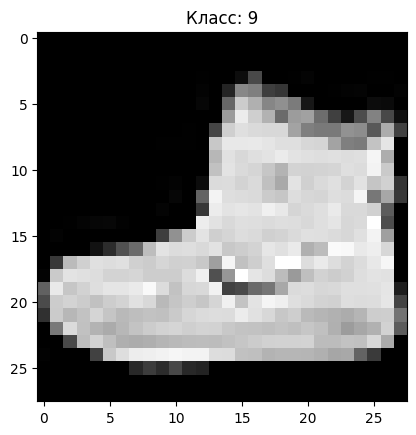

In [58]:
plt.imshow(X_train_full[0], cmap="gray")
plt.title(f"Класс: {y_train_full[0]}")
plt.show()

In [59]:
# Разворачиваем картинки 28x28 в вектор 784
X_train_full = X_train_full.reshape(X_train_full.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Нормализация: 0..255 -> 0..1
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("X_train_full:", X_train_full.shape)
print("X_test:", X_test.shape)
print("min/max:", X_train_full.min(), X_train_full.max())

X_train_full: (60000, 784)
X_test: (10000, 784)
min/max: 0.0 1.0


In [60]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X_train_full))

val_size = 10000
val_indices = indices[:val_size]
train_indices = indices[val_size:]

X_val = X_train_full[val_indices]
y_val = y_train_full[val_indices]

X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

print("X_train:", X_train.shape)   # (50000, 784)
print("X_val:", X_val.shape)       # (10000, 784)
print("X_test:", X_test.shape)     # (10000, 784)

X_train: (50000, 784)
X_val: (10000, 784)
X_test: (10000, 784)


In [61]:
# ===== АКТИВАЦИИ =====

def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1.0 - s)

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    t = np.tanh(x)
    return 1.0 - t ** 2

def relu(x):
    return np.maximum(0.0, x)

def relu_derivative(x):
    return (x > 0).astype(np.float32)


# def activation_forward(x, activation):
#     if activation == "sigmoid":
#         return sigmoid(x)
#     elif activation == "tanh":
#         return tanh(x)
#     elif activation == "relu":
#         return relu(x)
#     else:
#         raise ValueError(f"Неизвестная активация: {activation}")


# def activation_derivative(x, activation):
#     if activation == "sigmoid":
#         return sigmoid_derivative(x)
#     elif activation == "tanh":
#         return tanh_derivative(x)
#     elif activation == "relu":
#         return relu_derivative(x)
#     else:
#         raise ValueError(f"Неизвестная активация: {activation}")


print("Активации готовы")

Активации готовы


In [62]:
# Словарь: имя активации → (функция, производная)
ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_derivative),
    "tanh":    (tanh,    tanh_derivative),
    "relu":    (relu,    relu_derivative),
}

print("Словарь ACTIVATIONS готов:", list(ACTIVATIONS.keys()))

Словарь ACTIVATIONS готов: ['sigmoid', 'tanh', 'relu']


In [63]:
def initialize_weights(n_in, n_out, method, rng,
                       constant_value=0.01, std=0.01):
    if method == "constant":
        W = np.full((n_in, n_out), constant_value, dtype=np.float32)
    elif method == "zero":
        W = np.zeros((n_in, n_out), dtype=np.float32)
    elif method == "random":
        W = rng.normal(0.0, std, size=(n_in, n_out)).astype(np.float32)
    elif method == "xavier":
        s = np.sqrt(2.0 / (n_in + n_out))
        W = rng.normal(0.0, s, size=(n_in, n_out)).astype(np.float32)
    elif method == "kaiming":
        s = np.sqrt(2.0 / n_in)
        W = rng.normal(0.0, s, size=(n_in, n_out)).astype(np.float32)
    else:
        raise ValueError(f"Неизвестная инициализация: {method}")
    return W


print("Инициализация весов готова")

Инициализация весов готова


In [64]:
def softmax(logits):
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp = np.exp(shifted)
    return exp / np.sum(exp, axis=1, keepdims=True)


def cross_entropy_loss(logits, y_true):
    p = softmax(logits)
    n = logits.shape[0]
    correct = p[np.arange(n), y_true]
    return -np.mean(np.log(correct + 1e-12))


def cross_entropy_gradient(logits, y_true):
    p = softmax(logits)
    n = logits.shape[0]
    g = p.copy()
    g[np.arange(n), y_true] -= 1.0
    g /= n
    return g


print("Softmax и Cross-Entropy готовы")

Softmax и Cross-Entropy готовы


In [65]:
class MLP:
    def __init__(
        self,
        layers,
        activation="relu",
        weight_init="xavier",
        constant_value=0.01,
        std=0.01,
        bias_init="zero",
        bias_std=0.01,
        bias_constant=0.0,
        freeze_bias=False,
        dtype=np.float32,
        seed=42,
    ):
        self.layers = layers
        self.activation = activation

        if activation not in ACTIVATIONS:
            raise ValueError(f"Неизвестная активация: {activation}")
        self.act_fn, self.act_deriv = ACTIVATIONS[activation]

        self.weight_init = weight_init
        self.constant_value = constant_value
        self.std = std
        self.bias_init = bias_init
        self.freeze_bias = freeze_bias
        self.dtype = dtype

        self.rng = np.random.default_rng(seed)

        self.weights = []
        self.biases = []
        self.cache = {}
        self.dW = []
        self.db = []

        for i in range(len(layers) - 1):
            n_in, n_out = layers[i], layers[i + 1]

            W = initialize_weights(
                n_in, n_out, weight_init, self.rng,
                constant_value=constant_value, std=std,
            )

            if bias_init == "zero":
                b = np.zeros((1, n_out), dtype=dtype)
            elif bias_init == "normal":
                b = self.rng.normal(0.0, bias_std, size=(1, n_out)).astype(dtype)
            elif bias_init == "constant":
                b = np.full((1, n_out), bias_constant, dtype=dtype)
            else:
                raise ValueError(f"Неизвестный bias init: {bias_init}")

            self.weights.append(W)
            self.biases.append(b)

    def forward(self, X):
        self.cache = {"A": [X], "Z": []}
        A = X
        for i in range(len(self.weights)):
            Z = A @ self.weights[i] + self.biases[i]
            self.cache["Z"].append(Z)
            if i == len(self.weights) - 1:
                A = Z
            else:
                A = self.act_fn(Z)
            self.cache["A"].append(A)
        return A

    def backward(self, dL_dlogits):
        self.dW = [None] * len(self.weights)
        self.db = [None] * len(self.biases)
        gradient = dL_dlogits

        for i in reversed(range(len(self.weights))):
            A_prev = self.cache["A"][i]
            self.dW[i] = A_prev.T @ gradient
            self.db[i] = np.sum(gradient, axis=0, keepdims=True)

            if i > 0:
                dA_prev = gradient @ self.weights[i].T
                Z_prev = self.cache["Z"][i - 1]
                gradient = dA_prev * self.act_deriv(Z_prev)

    def step(self, learning_rate):
        for i in range(len(self.weights)):
            self.weights[i] -= learning_rate * self.dW[i]
            if not self.freeze_bias:
                self.biases[i] -= learning_rate * self.db[i]

    def zero_grad(self):
        self.dW = []
        self.db = []

    def parameters(self):
        return list(zip(self.weights, self.biases))

    def predict(self, X):
        logits = self.forward(X)
        return np.argmax(softmax(logits), axis=1)


print("Класс MLP готов (версия без диспетчеров)")

Класс MLP готов (версия без диспетчеров)


In [66]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def gradient_norm(model):
    total = 0.0
    for dW, db in zip(model.dW, model.db):
        total += np.sum(dW ** 2)
        total += np.sum(db ** 2)
    return float(np.sqrt(total))


print("Метрики готовы")

Метрики готовы


In [67]:
def train_one_epoch(model, X, y, batch_size, learning_rate, rng):
    indices = rng.permutation(len(X))
    total_loss = 0.0
    num_batches = 0
    all_preds = []
    all_true = []
    grad_norms = []

    for start in range(0, len(X), batch_size):
        idx = indices[start:start + batch_size]
        X_batch = X[idx]
        y_batch = y[idx]

        logits = model.forward(X_batch)
        loss = cross_entropy_loss(logits, y_batch)
        preds = np.argmax(logits, axis=1)

        grad = cross_entropy_gradient(logits, y_batch)
        model.backward(grad)
        grad_norms.append(gradient_norm(model))
        model.step(learning_rate)

        total_loss += loss
        num_batches += 1
        all_preds.append(preds)
        all_true.append(y_batch)

    all_preds = np.concatenate(all_preds)
    all_true = np.concatenate(all_true)

    m = calculate_metrics(all_true, all_preds)
    m["loss"] = total_loss / num_batches
    m["grad_norm"] = float(np.mean(grad_norms))
    return m


def evaluate(model, X, y, batch_size=256):
    total_loss = 0.0
    num_batches = 0
    all_preds = []
    grad_norms = []

    for start in range(0, len(X), batch_size):
        X_batch = X[start:start + batch_size]
        y_batch = y[start:start + batch_size]

        logits = model.forward(X_batch)
        loss = cross_entropy_loss(logits, y_batch)
        preds = np.argmax(logits, axis=1)

        grad = cross_entropy_gradient(logits, y_batch)
        model.backward(grad)
        grad_norms.append(gradient_norm(model))

        total_loss += loss
        num_batches += 1
        all_preds.append(preds)

    all_preds = np.concatenate(all_preds)
    m = calculate_metrics(y, all_preds)
    m["loss"] = total_loss / num_batches
    m["grad_norm"] = float(np.mean(grad_norms))
    return m


print("Обучение готово")

Обучение готово


In [68]:
def run_experiment(
    name,
    layers,
    activation,
    weight_init,
    batch_size,
    learning_rate,
    num_epochs,
    seed=42,
    constant_value=0.01,
    std=0.01,
    bias_init="zero",
    bias_std=0.01,
    bias_constant=0.0,
    freeze_bias=False,
    verbose=True,
):
    train_rng = np.random.default_rng(seed + 1)

    model = MLP(
        layers=layers,
        activation=activation,
        weight_init=weight_init,
        constant_value=constant_value,
        std=std,
        bias_init=bias_init,
        bias_std=bias_std,
        bias_constant=bias_constant,
        freeze_bias=freeze_bias,
        seed=seed,
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_accuracy": [], "val_accuracy": [],
        "train_precision": [], "val_precision": [],
        "train_recall": [], "val_recall": [],
        "train_f1": [], "val_f1": [],
        "train_grad_norm": [], "val_grad_norm": [],
    }

    for epoch in range(num_epochs):
        tr = train_one_epoch(model, X_train, y_train,
                             batch_size, learning_rate, train_rng)
        vl = evaluate(model, X_val, y_val, batch_size=256)

        history["train_loss"].append(tr["loss"])
        history["val_loss"].append(vl["loss"])
        history["train_accuracy"].append(tr["accuracy"])
        history["val_accuracy"].append(vl["accuracy"])
        history["train_precision"].append(tr["precision"])
        history["val_precision"].append(vl["precision"])
        history["train_recall"].append(tr["recall"])
        history["val_recall"].append(vl["recall"])
        history["train_f1"].append(tr["f1"])
        history["val_f1"].append(vl["f1"])
        history["train_grad_norm"].append(tr["grad_norm"])
        history["val_grad_norm"].append(vl["grad_norm"])

        if verbose:
            print(f"[{name}] Эпоха {epoch+1}/{num_epochs} | "
                  f"train loss={tr['loss']:.4f} acc={tr['accuracy']:.4f} | "
                  f"val loss={vl['loss']:.4f} acc={vl['accuracy']:.4f} f1={vl['f1']:.4f}")

    return model, history


print("run_experiment готов")

run_experiment готов


In [69]:
# Проверяем, что всё в памяти
checks = [
    ("np", "import numpy as np"),
    ("SEED", "SEED = 42"),
    ("X_train", "подготовка данных"),
    ("y_train", "подготовка данных"),
    ("X_val", "разделение train/val"),
    ("sigmoid", "функции активации"),
    ("ACTIVATIONS", "словарь активаций"),
    ("MLP", "класс MLP"),
    ("calculate_metrics", "метрики"),
    ("train_one_epoch", "обучение одной эпохи"),
    ("evaluate", "валидация"),
    ("run_experiment", "обёртка эксперимента"),
]

missing = []
for name, where in checks:
    try:
        eval(name)
        print(f"✅ {name:20s} — OK")
    except NameError:
        print(f"❌ {name:20s} — нет (нужно выполнить ячейку: {where})")
        missing.append(name)

if missing:
    print(f"\n⚠️ Пропущено: {len(missing)} объектов")
    print("Нужно выполнить ячейки сверху вниз по порядку, где они определяются")
else:
    print("\n🎉 Всё готово, можно запускать smoke_test_v2")

✅ np                   — OK
✅ SEED                 — OK
✅ X_train              — OK
✅ y_train              — OK
✅ X_val                — OK
✅ sigmoid              — OK
✅ ACTIVATIONS          — OK
✅ MLP                  — OK
✅ calculate_metrics    — OK
✅ train_one_epoch      — OK
✅ evaluate             — OK
✅ run_experiment       — OK

🎉 Всё готово, можно запускать smoke_test_v2


In [70]:
model, hist = run_experiment(
    name="smoke_test",
    layers=[784, 100, 50, 10],
    activation="relu",
    weight_init="xavier",
    batch_size=64,
    learning_rate=0.01,
    num_epochs=2,
    seed=SEED,
)

[smoke_test] Эпоха 1/2 | train loss=0.9811 acc=0.6782 | val loss=0.6583 acc=0.7661 f1=0.7499
[smoke_test] Эпоха 2/2 | train loss=0.6065 acc=0.7937 | val loss=0.5539 acc=0.8093 f1=0.8098


In [71]:
required_configs = [
    dict(name="exp1", layers=[784,100,50,10],           weight_init="random",
         activation="sigmoid", batch_size=16, learning_rate=0.1,  num_epochs=35),
    dict(name="exp2", layers=[784,100,50,10],           weight_init="random",
         activation="sigmoid", batch_size=32, learning_rate=0.01, num_epochs=15),
    dict(name="exp3", layers=[784,392,196,98,10],       weight_init="xavier",
         activation="tanh",    batch_size=32, learning_rate=0.01, num_epochs=15),
    dict(name="exp4", layers=[784,392,196,98,49,25,10], weight_init="kaiming",
         activation="relu",    batch_size=64, learning_rate=0.01, num_epochs=15),
]

results = {}

print("Конфигурации заданы:", [c["name"] for c in required_configs])

Конфигурации заданы: ['exp1', 'exp2', 'exp3', 'exp4']


In [72]:
# Основной цикл запуска (можно запускать частями)
for cfg in required_configs:
    cfg = cfg.copy()   # не портим исходник
    name = cfg.pop("name")
    print(f"\n{'='*60}\nЗапуск {name}: {cfg}\n{'='*60}")
    model, hist = run_experiment(name=name, **cfg)
    results[name] = {"config": cfg, "model": model, "history": hist}
    print(f"{name} завершён\n")


Запуск exp1: {'layers': [784, 100, 50, 10], 'weight_init': 'random', 'activation': 'sigmoid', 'batch_size': 16, 'learning_rate': 0.1, 'num_epochs': 35}
[exp1] Эпоха 1/35 | train loss=2.0381 acc=0.1826 | val loss=1.5465 acc=0.3112 f1=0.2260
[exp1] Эпоха 2/35 | train loss=1.1276 acc=0.5594 | val loss=0.7830 acc=0.6939 f1=0.6588
[exp1] Эпоха 3/35 | train loss=0.6767 acc=0.7450 | val loss=0.5539 acc=0.7935 f1=0.7819
[exp1] Эпоха 4/35 | train loss=0.5279 acc=0.8107 | val loss=0.4778 acc=0.8235 f1=0.8127
[exp1] Эпоха 5/35 | train loss=0.4661 acc=0.8355 | val loss=0.4367 acc=0.8411 f1=0.8364
[exp1] Эпоха 6/35 | train loss=0.4297 acc=0.8463 | val loss=0.4275 acc=0.8450 f1=0.8432
[exp1] Эпоха 7/35 | train loss=0.4049 acc=0.8544 | val loss=0.3971 acc=0.8532 f1=0.8511
[exp1] Эпоха 8/35 | train loss=0.3854 acc=0.8630 | val loss=0.3835 acc=0.8600 f1=0.8579
[exp1] Эпоха 9/35 | train loss=0.3696 acc=0.8665 | val loss=0.3614 acc=0.8679 f1=0.8679
[exp1] Эпоха 10/35 | train loss=0.3559 acc=0.8714 | val

In [73]:
def summarize(name, results):
    r = results[name]
    cfg = r["config"]
    h = r["history"]
    return {
        "exp": name,
        "architecture": str(cfg.get("layers")),
        "init": cfg.get("weight_init"),
        "activation": cfg.get("activation"),
        "bias_init": cfg.get("bias_init", "zero"),
        "batch": cfg.get("batch_size"),
        "lr": cfg.get("learning_rate"),
        "epochs": cfg.get("num_epochs"),
        "train_loss": round(h["train_loss"][-1], 4),
        "val_loss": round(h["val_loss"][-1], 4),
        "val_acc": round(h["val_accuracy"][-1], 4),
        "val_f1": round(h["val_f1"][-1], 4),
        "grad": round(h["train_grad_norm"][-1], 4),
    }

summary_rows = [summarize(name, results) for name in results]

header = f"{'exp':6s} {'arch':30s} {'init':10s} {'act':8s} {'bs':>4s} {'lr':>6s} {'ep':>4s} {'tr_loss':>8s} {'val_loss':>9s} {'val_acc':>8s} {'val_f1':>8s} {'grad':>8s}"
print(header)
print("-" * len(header))
for r in summary_rows:
    print(f"{r['exp']:6s} {r['architecture']:30s} {r['init']:10s} {r['activation']:8s} "
          f"{r['batch']:>4d} {r['lr']:>6.3f} {r['epochs']:>4d} "
          f"{r['train_loss']:>8.4f} {r['val_loss']:>9.4f} {r['val_acc']:>8.4f} "
          f"{r['val_f1']:>8.4f} {r['grad']:>8.4f}")

# Сохраняем CSV
if summary_rows:
    with open("experiment_summary.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=summary_rows[0].keys())
        w.writeheader()
        w.writerows(summary_rows)
    print("\nСохранено: experiment_summary.csv")

exp    arch                           init       act        bs     lr   ep  tr_loss  val_loss  val_acc   val_f1     grad
------------------------------------------------------------------------------------------------------------------------
exp1   [784, 100, 50, 10]             random     sigmoid    16  0.100   35   0.2245    0.3056   0.8882   0.8876   1.0014
exp2   [784, 100, 50, 10]             random     sigmoid    32  0.010   15   1.6414    1.6101   0.3039   0.2275   0.6195
exp3   [784, 392, 196, 98, 10]        xavier     tanh       32  0.010   15   0.2991    0.3301   0.8767   0.8743   2.3846
exp4   [784, 392, 196, 98, 49, 25, 10] kaiming    relu       64  0.010   15   0.2733    0.3306   0.8789   0.8763   3.2557

Сохранено: experiment_summary.csv


In [74]:
def plot_experiment(name, hist):
    epochs = np.arange(1, len(hist["train_loss"]) + 1)

    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    fig.suptitle(f"Experiment {name}", fontsize=14)

    pairs = [
        ("loss", "Loss"),
        ("accuracy", "Accuracy"),
        ("precision", "Precision (macro)"),
        ("recall", "Recall (macro)"),
        ("f1", "F1 (macro)"),
        ("grad_norm", "Gradient L2 norm"),
    ]

    for ax, (key, title) in zip(axes.flat, pairs):
        ax.plot(epochs, hist[f"train_{key}"], marker="o", label="Train")
        ax.plot(epochs, hist[f"val_{key}"], marker="o", label="Validation")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.set_title(title)
        ax.grid(True)
        ax.legend()

    plt.tight_layout()
    plt.show()

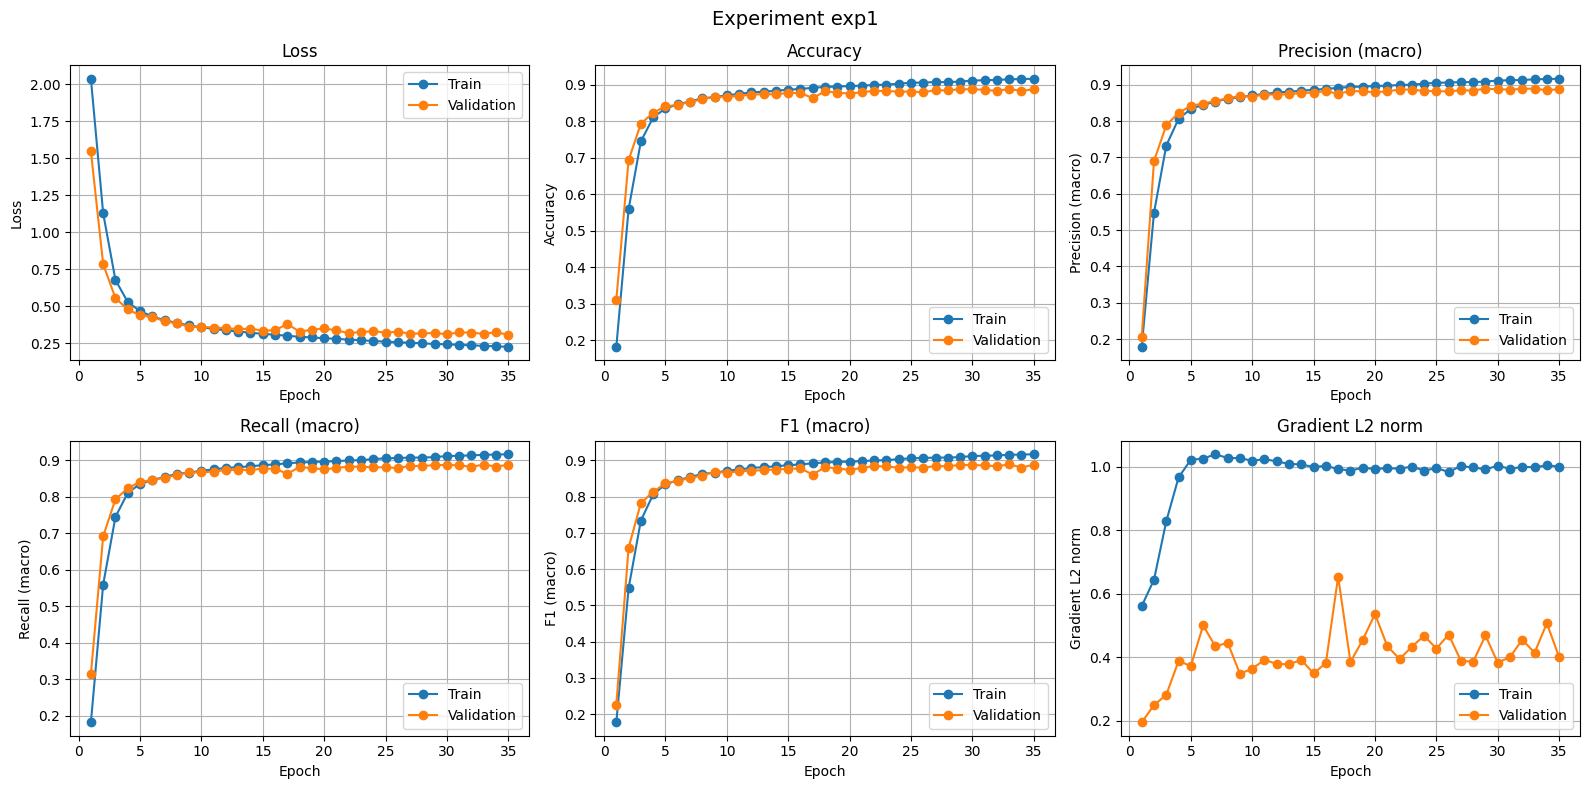

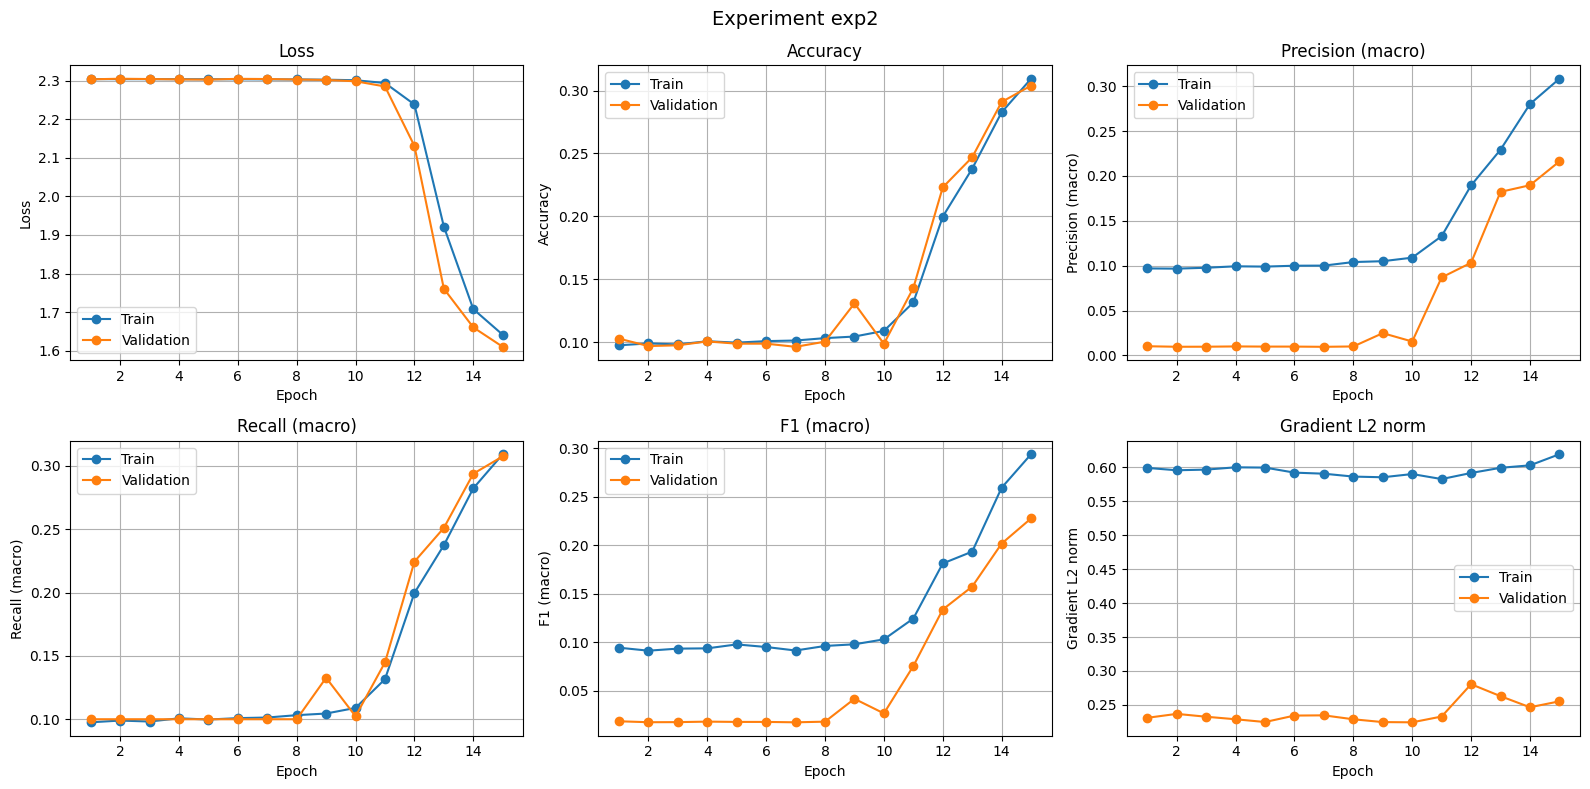

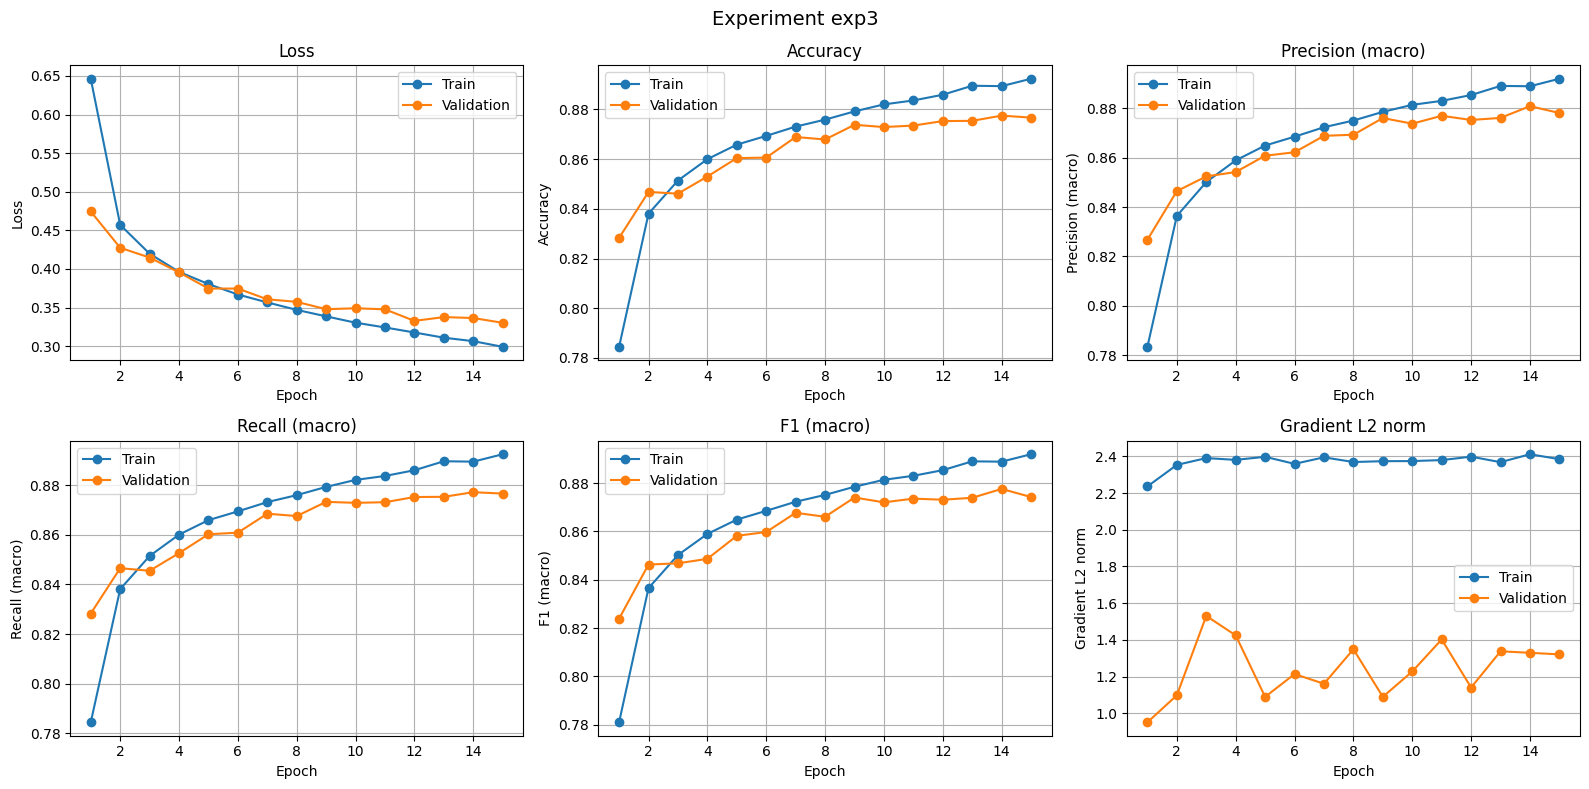

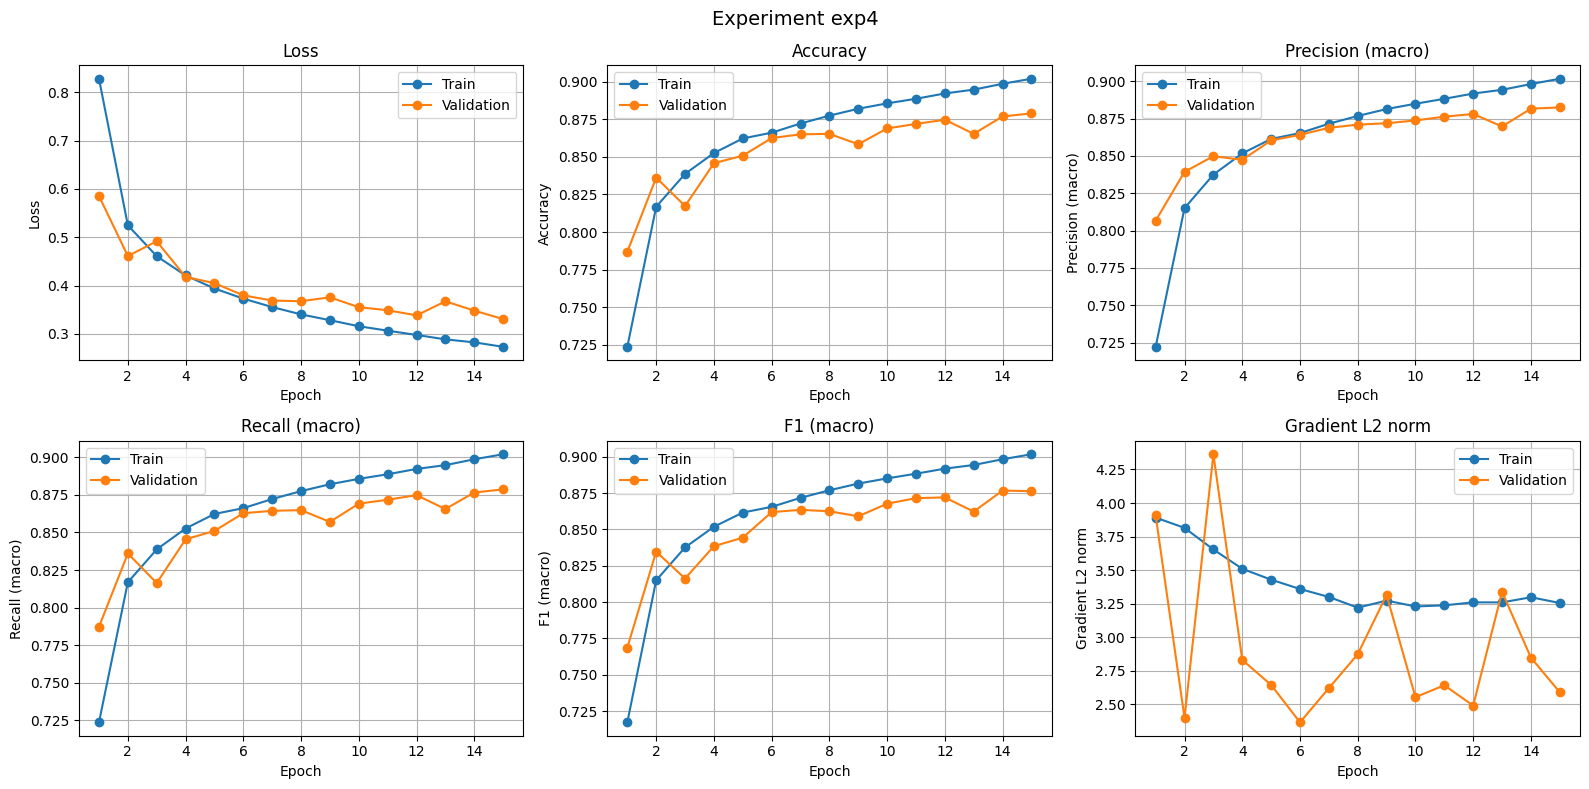

In [75]:
for name in results:
    plot_experiment(name, results[name]["history"])

In [76]:
import numpy as np
for name in list(results.keys()):
    hist = results[name]["history"]
    np.savez(f"{name}_history.npz", **{k: np.array(v) for k, v in hist.items()})
    print(f"{name}: сохранён")

exp1: сохранён
exp2: сохранён
exp3: сохранён
exp4: сохранён


In [77]:
hyp1_common = dict(
    layers=[784, 196, 98, 49, 10],   # 3 скрытых слоя — достаточно "глубоко"
    weight_init="xavier",             # одинаково для всех
    batch_size=64,
    learning_rate=0.01,
    num_epochs=10,
    seed=SEED,
)

hyp1_configs = [
    dict(name="h1_sigmoid", activation="sigmoid", **hyp1_common),
    dict(name="h1_tanh",    activation="tanh",    **hyp1_common),
    dict(name="h1_relu",    activation="relu",    **hyp1_common),
]

hyp1_results = {}
print("H1 конфигурации готовы:", [c["name"] for c in hyp1_configs])

H1 конфигурации готовы: ['h1_sigmoid', 'h1_tanh', 'h1_relu']


Гипотезы

Гипотеза 1: sigmoid и глубина сети

In [78]:
for cfg in hyp1_configs:
    cfg = cfg.copy()
    name = cfg.pop("name")
    print(f"\n{'='*60}\nЗапуск {name}\n{'='*60}")
    model, hist = run_experiment(name=name, **cfg)
    hyp1_results[name] = {"config": cfg, "model": model, "history": hist}
    print(f"{name} завершён")


Запуск h1_sigmoid
[h1_sigmoid] Эпоха 1/10 | train loss=2.3035 acc=0.1349 | val loss=2.2879 acc=0.1772 f1=0.0976
[h1_sigmoid] Эпоха 2/10 | train loss=2.2784 acc=0.2223 | val loss=2.2672 acc=0.2439 f1=0.1335
[h1_sigmoid] Эпоха 3/10 | train loss=2.2490 acc=0.2958 | val loss=2.2260 acc=0.3308 f1=0.2454
[h1_sigmoid] Эпоха 4/10 | train loss=2.1863 acc=0.3353 | val loss=2.1301 acc=0.3225 f1=0.2340
[h1_sigmoid] Эпоха 5/10 | train loss=2.0397 acc=0.3575 | val loss=1.9263 acc=0.3871 f1=0.2945
[h1_sigmoid] Эпоха 6/10 | train loss=1.8163 acc=0.3925 | val loss=1.7064 acc=0.3981 f1=0.3170
[h1_sigmoid] Эпоха 7/10 | train loss=1.6182 acc=0.4385 | val loss=1.5261 acc=0.4945 f1=0.4099
[h1_sigmoid] Эпоха 8/10 | train loss=1.4509 acc=0.5116 | val loss=1.3764 acc=0.5342 f1=0.4726
[h1_sigmoid] Эпоха 9/10 | train loss=1.3247 acc=0.5500 | val loss=1.2727 acc=0.5581 f1=0.5336
[h1_sigmoid] Эпоха 10/10 | train loss=1.2384 acc=0.5684 | val loss=1.1984 acc=0.5837 f1=0.5369
h1_sigmoid завершён

Запуск h1_tanh
[h1_

In [79]:
import numpy as np
for name, r in hyp1_results.items():
    hist = r["history"]
    np.savez(f"{name}_history.npz", **{k: np.array(v) for k, v in hist.items()})
    print(f"{name}: сохранён, эпох = {len(hist['train_loss'])}")

h1_sigmoid: сохранён, эпох = 10
h1_tanh: сохранён, эпох = 10
h1_relu: сохранён, эпох = 10


Гипотеза 4: нулевая инициализация смещений

In [80]:
hyp4_common = dict(
    layers=[784, 196, 98, 10],
    activation="relu",
    weight_init="kaiming",
    batch_size=64,
    learning_rate=0.01,
    num_epochs=10,
    seed=SEED,
)

hyp4_configs = [
    dict(name="h4_bias_zero",   bias_init="zero",   **hyp4_common),
    dict(name="h4_bias_normal", bias_init="normal", bias_std=0.01, **hyp4_common),
    dict(name="h4_bias_frozen", bias_init="zero",   freeze_bias=True, **hyp4_common),
]

hyp4_results = {}
print("H4 готов:", [c["name"] for c in hyp4_configs])

H4 готов: ['h4_bias_zero', 'h4_bias_normal', 'h4_bias_frozen']


In [81]:
for cfg in hyp4_configs:
    cfg = cfg.copy()
    name = cfg.pop("name")
    print(f"\n{'='*60}\nЗапуск {name}\n{'='*60}")
    model, hist = run_experiment(name=name, **cfg)
    hyp4_results[name] = {"config": cfg, "model": model, "history": hist}
    print(f"{name} завершён")


Запуск h4_bias_zero
[h4_bias_zero] Эпоха 1/10 | train loss=0.8556 acc=0.7256 | val loss=0.5898 acc=0.7961 f1=0.7859
[h4_bias_zero] Эпоха 2/10 | train loss=0.5469 acc=0.8164 | val loss=0.5106 acc=0.8202 f1=0.8210
[h4_bias_zero] Эпоха 3/10 | train loss=0.4926 acc=0.8294 | val loss=0.4770 acc=0.8301 f1=0.8307
[h4_bias_zero] Эпоха 4/10 | train loss=0.4615 acc=0.8402 | val loss=0.4566 acc=0.8357 f1=0.8286
[h4_bias_zero] Эпоха 5/10 | train loss=0.4419 acc=0.8462 | val loss=0.4492 acc=0.8394 f1=0.8331
[h4_bias_zero] Эпоха 6/10 | train loss=0.4264 acc=0.8515 | val loss=0.4225 acc=0.8498 f1=0.8479
[h4_bias_zero] Эпоха 7/10 | train loss=0.4134 acc=0.8552 | val loss=0.4249 acc=0.8482 f1=0.8469
[h4_bias_zero] Эпоха 8/10 | train loss=0.4017 acc=0.8590 | val loss=0.4152 acc=0.8500 f1=0.8477
[h4_bias_zero] Эпоха 9/10 | train loss=0.3922 acc=0.8626 | val loss=0.3947 acc=0.8581 f1=0.8586
[h4_bias_zero] Эпоха 10/10 | train loss=0.3833 acc=0.8663 | val loss=0.3967 acc=0.8569 f1=0.8541
h4_bias_zero завер

In [82]:
import numpy as np
for name, r in hyp4_results.items():
    hist = r["history"]
    np.savez(f"{name}_history.npz", **{k: np.array(v) for k, v in hist.items()})
    print(f"{name}: сохранён")

h4_bias_zero: сохранён
h4_bias_normal: сохранён
h4_bias_frozen: сохранён


Гипотеза 6. Размер mini-batch

In [83]:
hyp6_common = dict(
    layers=[784, 196, 98, 10],
    activation="relu",
    weight_init="kaiming",
    learning_rate=0.01,
    num_epochs=10,
    seed=SEED,
)

hyp6_configs = [
    dict(name="h6_bs16",  batch_size=16,  **hyp6_common),
    dict(name="h6_bs64",  batch_size=64,  **hyp6_common),
    dict(name="h6_bs256", batch_size=256, **hyp6_common),
]

hyp6_results = {}
print("H6 готов:", [c["name"] for c in hyp6_configs])

H6 готов: ['h6_bs16', 'h6_bs64', 'h6_bs256']


In [84]:
for cfg in hyp6_configs:
    cfg = cfg.copy()
    name = cfg.pop("name")
    print(f"\n{'='*60}\nЗапуск {name}\n{'='*60}")
    model, hist = run_experiment(name=name, **cfg)
    hyp6_results[name] = {"config": cfg, "model": model, "history": hist}
    print(f"{name} завершён")


Запуск h6_bs16
[h6_bs16] Эпоха 1/10 | train loss=0.6252 acc=0.7866 | val loss=0.4614 acc=0.8346 f1=0.8305
[h6_bs16] Эпоха 2/10 | train loss=0.4484 acc=0.8425 | val loss=0.4069 acc=0.8540 f1=0.8538
[h6_bs16] Эпоха 3/10 | train loss=0.4057 acc=0.8560 | val loss=0.3971 acc=0.8567 f1=0.8582
[h6_bs16] Эпоха 4/10 | train loss=0.3772 acc=0.8666 | val loss=0.3738 acc=0.8629 f1=0.8592
[h6_bs16] Эпоха 5/10 | train loss=0.3577 acc=0.8721 | val loss=0.3512 acc=0.8728 f1=0.8704
[h6_bs16] Эпоха 6/10 | train loss=0.3417 acc=0.8776 | val loss=0.3624 acc=0.8693 f1=0.8694
[h6_bs16] Эпоха 7/10 | train loss=0.3292 acc=0.8812 | val loss=0.3360 acc=0.8783 f1=0.8768
[h6_bs16] Эпоха 8/10 | train loss=0.3159 acc=0.8871 | val loss=0.3332 acc=0.8780 f1=0.8767
[h6_bs16] Эпоха 9/10 | train loss=0.3063 acc=0.8896 | val loss=0.3209 acc=0.8821 f1=0.8814
[h6_bs16] Эпоха 10/10 | train loss=0.2954 acc=0.8935 | val loss=0.3282 acc=0.8785 f1=0.8773
h6_bs16 завершён

Запуск h6_bs64
[h6_bs64] Эпоха 1/10 | train loss=0.8556

In [85]:
import numpy as np
for name, r in hyp6_results.items():
    hist = r["history"]
    np.savez(f"{name}_history.npz", **{k: np.array(v) for k, v in hist.items()})
    print(f"{name}: сохранён")

h6_bs16: сохранён
h6_bs64: сохранён
h6_bs256: сохранён


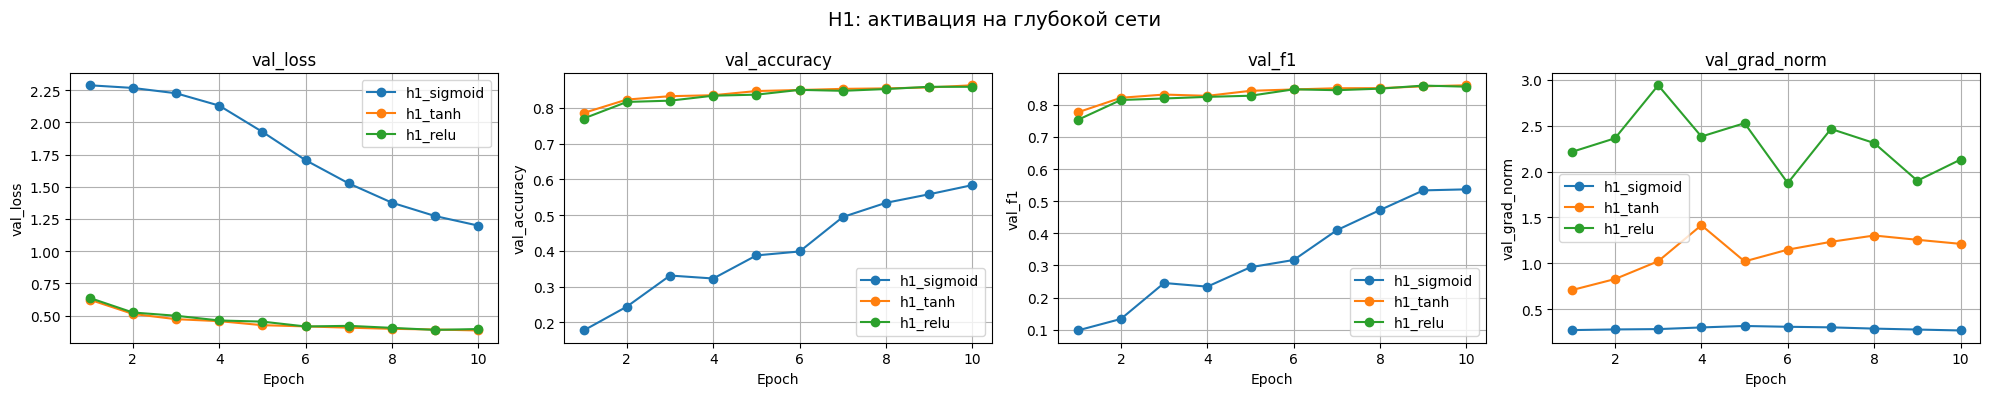

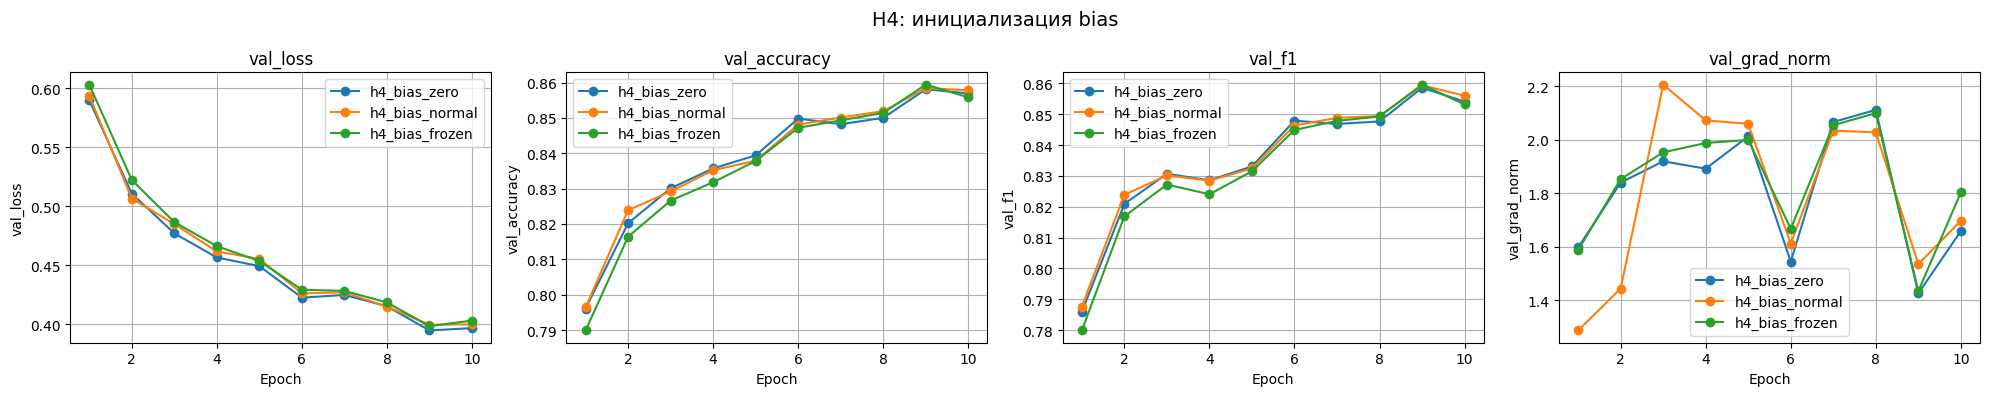

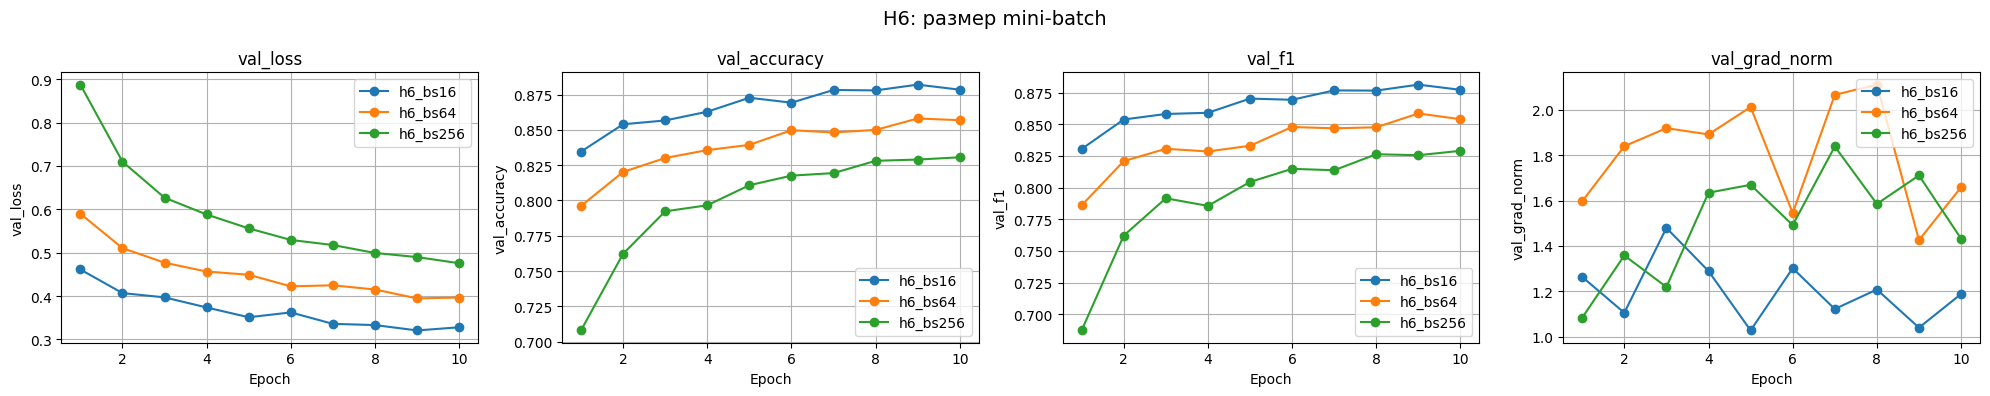

In [86]:
def plot_group(group_results, title,
               metric_keys=("val_loss", "val_accuracy", "val_f1", "val_grad_norm")):
    fig, axes = plt.subplots(1, len(metric_keys), figsize=(5*len(metric_keys), 4))
    if len(metric_keys) == 1:
        axes = [axes]
    fig.suptitle(title, fontsize=14)
    for ax, key in zip(axes, metric_keys):
        for name, r in group_results.items():
            h = r["history"]
            ax.plot(range(1, len(h[key])+1), h[key], marker="o", label=name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(key)
        ax.set_title(key)
        ax.grid(True)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_group(hyp1_results, "H1: активация на глубокой сети")
plot_group(hyp4_results, "H4: инициализация bias")
plot_group(hyp6_results, "H6: размер mini-batch")

In [87]:
def summarize_short(name, results_dict, hypothesis=""):
    r = results_dict[name]
    cfg = r["config"]
    h = r["history"]
    return {
        "experiment": name,
        "hypothesis": hypothesis,
        "architecture": str(cfg.get("layers")),
        "init": cfg.get("weight_init"),
        "activation": cfg.get("activation"),
        "bias_init": cfg.get("bias_init", "zero"),
        "batch": cfg.get("batch_size"),
        "lr": cfg.get("learning_rate"),
        "epochs": cfg.get("num_epochs"),
        "val_loss": round(h["val_loss"][-1], 4),
        "val_acc": round(h["val_accuracy"][-1], 4),
        "val_f1": round(h["val_f1"][-1], 4),
    }

hyp_rows = []
for name in hyp1_results: hyp_rows.append(summarize_short(name, hyp1_results, "H1"))
for name in hyp4_results: hyp_rows.append(summarize_short(name, hyp4_results, "H4"))
for name in hyp6_results: hyp_rows.append(summarize_short(name, hyp6_results, "H6"))

import csv
with open("hypotheses_results.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=hyp_rows[0].keys())
    w.writeheader()
    w.writerows(hyp_rows)

for r in hyp_rows:
    print(f"{r['experiment']:15s} {r['hypothesis']:4s} act={r['activation']:8s} "
          f"bias={r['bias_init']:8s} bs={r['batch']:>4d} "
          f"val_loss={r['val_loss']:.4f} val_acc={r['val_acc']:.4f} val_f1={r['val_f1']:.4f}")

print("\nСохранено: hypotheses_results.csv")

h1_sigmoid      H1   act=sigmoid  bias=zero     bs=  64 val_loss=1.1984 val_acc=0.5837 val_f1=0.5369
h1_tanh         H1   act=tanh     bias=zero     bs=  64 val_loss=0.3848 val_acc=0.8628 val_f1=0.8608
h1_relu         H1   act=relu     bias=zero     bs=  64 val_loss=0.3960 val_acc=0.8585 val_f1=0.8565
h4_bias_zero    H4   act=relu     bias=zero     bs=  64 val_loss=0.3967 val_acc=0.8569 val_f1=0.8541
h4_bias_normal  H4   act=relu     bias=normal   bs=  64 val_loss=0.3999 val_acc=0.8578 val_f1=0.8560
h4_bias_frozen  H4   act=relu     bias=zero     bs=  64 val_loss=0.4031 val_acc=0.8558 val_f1=0.8532
h6_bs16         H6   act=relu     bias=zero     bs=  16 val_loss=0.3282 val_acc=0.8785 val_f1=0.8773
h6_bs64         H6   act=relu     bias=zero     bs=  64 val_loss=0.3967 val_acc=0.8569 val_f1=0.8541
h6_bs256        H6   act=relu     bias=zero     bs= 256 val_loss=0.4758 val_acc=0.8306 val_f1=0.8291

Сохранено: hypotheses_results.csv


зануленое смещение

In [88]:
exp1_no_bias_model, exp1_no_bias_hist = run_experiment(
    name="exp1_not_bias",
    layers=[784, 100, 50, 10],
    activation="sigmoid",
    weight_init="random",
    batch_size=16,
    learning_rate=0.1,
    num_epochs=35,
    bias_init="zero",
    freeze_bias=True,
    seed=SEED,
    verbose=True
)

[exp1_not_bias] Эпоха 1/35 | train loss=2.0597 acc=0.1773 | val loss=1.5092 acc=0.3329 f1=0.2464
[exp1_not_bias] Эпоха 2/35 | train loss=1.0649 acc=0.5828 | val loss=0.7116 acc=0.7202 f1=0.6974
[exp1_not_bias] Эпоха 3/35 | train loss=0.6257 acc=0.7651 | val loss=0.5139 acc=0.8142 f1=0.8118
[exp1_not_bias] Эпоха 4/35 | train loss=0.4940 acc=0.8230 | val loss=0.4640 acc=0.8299 f1=0.8200
[exp1_not_bias] Эпоха 5/35 | train loss=0.4464 acc=0.8412 | val loss=0.4268 acc=0.8460 f1=0.8417
[exp1_not_bias] Эпоха 6/35 | train loss=0.4172 acc=0.8507 | val loss=0.4242 acc=0.8454 f1=0.8438
[exp1_not_bias] Эпоха 7/35 | train loss=0.3963 acc=0.8580 | val loss=0.3875 acc=0.8569 f1=0.8553
[exp1_not_bias] Эпоха 8/35 | train loss=0.3779 acc=0.8648 | val loss=0.3822 acc=0.8589 f1=0.8572
[exp1_not_bias] Эпоха 9/35 | train loss=0.3636 acc=0.8704 | val loss=0.3620 acc=0.8664 f1=0.8663
[exp1_not_bias] Эпоха 10/35 | train loss=0.3506 acc=0.8737 | val loss=0.3648 acc=0.8673 f1=0.8662
[exp1_not_bias] Эпоха 11/35 |

Таблицы

In [89]:
for name in ["results", "hyp1_results", "hyp4_results", "hyp6_results"]:
    try:
        eval(name)
        print(f"✅ {name}")
    except NameError:
        print(f"❌ {name} — не определён")

✅ results
✅ hyp1_results
✅ hyp4_results
✅ hyp6_results


In [90]:
# ============================================================
# ВЫВОД ВСЕХ ТАБЛИЦ РЕЗУЛЬТАТОВ ПРЯМО В COLAB
# ============================================================

from IPython.display import display, HTML


def summarize_table(name, results_dict, hypothesis=""):
    r = results_dict[name]
    cfg = r["config"]
    h = r["history"]
    return {
        "experiment": name,
        "hypothesis": hypothesis,
        "architecture": str(cfg.get("layers", "?")),
        "init": cfg.get("weight_init", "?"),
        "activation": cfg.get("activation", "?"),
        "bias": cfg.get("bias_init", "zero") + ("+frozen" if cfg.get("freeze_bias") else ""),
        "batch": cfg.get("batch_size", "?"),
        "lr": cfg.get("learning_rate", "?"),
        "epochs": cfg.get("num_epochs", "?"),
        "train_loss": round(h["train_loss"][-1], 4),
        "val_loss": round(h["val_loss"][-1], 4),
        "val_acc": round(h["val_accuracy"][-1], 4),
        "val_f1": round(h["val_f1"][-1], 4),
        "grad_norm": round(h["train_grad_norm"][-1], 4),
    }


def display_table(rows, title="", highlight_best=None):
    if not rows:
        display(HTML(f"<p>Нет данных для «{title}»</p>"))
        return

    headers = list(rows[0].keys())

    best_value = None
    if highlight_best:
        best_value = max(r[highlight_best] for r in rows)

    html = """
    <style>
        .exp-table { border-collapse: collapse; font-family: monospace; font-size: 12px; margin: 10px 0; }
        .exp-table th { background: #2c3e50; color: white; padding: 8px; text-align: left; }
        .exp-table td { padding: 6px 8px; border-bottom: 1px solid #ddd; }
        .exp-table tr:nth-child(even) { background: #f8f9fa; }
        .exp-table tr:hover { background: #e8f4f8; }
        .best { background: #d4edda !important; font-weight: bold; }
        .title { font-size: 16px; font-weight: bold; margin: 20px 0 5px 0; color: #2c3e50; }
    </style>
    """

    if title:
        html += f'<div class="title">{title}</div>'

    html += '<table class="exp-table">'
    html += "<tr>" + "".join(f"<th>{h}</th>" for h in headers) + "</tr>"

    for r in rows:
        row_class = ' class="best"' if (highlight_best and r[highlight_best] == best_value) else ""
        html += f"<tr{row_class}>"
        for h in headers:
            html += f"<td>{r[h]}</td>"
        html += "</tr>"
    html += "</table>"

    display(HTML(html))


# ============================================================
# 1. Обязательные 4 эксперимента
# ============================================================
try:
    rows = [summarize_table(name, results) for name in results]
    display_table(rows, "Обязательные эксперименты", highlight_best="val_acc")
except NameError as e:
    print(f"⚠️ results не определён: {e}")


# ============================================================
# 2. Гипотеза 1
# ============================================================
try:
    rows = [summarize_table(name, hyp1_results, "H1") for name in hyp1_results]
    display_table(rows, "Гипотеза 1: активация на глубокой сети", highlight_best="val_acc")
except NameError as e:
    print(f"⚠️ hyp1_results не определён: {e}")


# ============================================================
# 3. Гипотеза 4 (включая доп. эксперименты)
# ============================================================
try:
    rows = [summarize_table(name, hyp4_results, "H4") for name in hyp4_results]
    display_table(rows, "Гипотеза 4: инициализация bias", highlight_best="val_acc")
except NameError as e:
    print(f"⚠️ hyp4_results не определён: {e}")


# ============================================================
# 4. Гипотеза 6
# ============================================================
try:
    rows = [summarize_table(name, hyp6_results, "H6") for name in hyp6_results]
    display_table(rows, "Гипотеза 6: размер mini-batch", highlight_best="val_acc")
except NameError as e:
    print(f"⚠️ hyp6_results не определён: {e}")


# ============================================================
# 5. Сводная таблица по всем 13+ экспериментам
# ============================================================
all_rows = []

for name in results:
    all_rows.append(summarize_table(name, results, "oblig"))

for name in hyp1_results:
    all_rows.append(summarize_table(name, hyp1_results, "H1"))

for name in hyp4_results:
    all_rows.append(summarize_table(name, hyp4_results, "H4"))

for name in hyp6_results:
    all_rows.append(summarize_table(name, hyp6_results, "H6"))

# Если есть дополнительные эксперименты — добавь их тоже
try:
    if "exp1_no_bias" in globals() and exp1_no_bias_hist is not None:
        all_rows.append({
            "experiment": "exp1_no_bias",
            "hypothesis": "extra",
            "architecture": "[784,100,50,10]",
            "init": "random",
            "activation": "sigmoid",
            "bias": "zero+frozen",
            "batch": 16,
            "lr": 0.1,
            "epochs": 35,
            "train_loss": round(exp1_no_bias_hist["train_loss"][-1], 4),
            "val_loss": round(exp1_no_bias_hist["val_loss"][-1], 4),
            "val_acc": round(exp1_no_bias_hist["val_accuracy"][-1], 4),
            "val_f1": round(exp1_no_bias_hist["val_f1"][-1], 4),
            "grad_norm": round(exp1_no_bias_hist["train_grad_norm"][-1], 4),
        })
except NameError:
    pass

display_table(all_rows, "ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ВСЕХ ЭКСПЕРИМЕНТОВ", highlight_best="val_acc")

experiment,hypothesis,architecture,init,activation,bias,batch,lr,epochs,train_loss,val_loss,val_acc,val_f1,grad_norm
exp1,,"[784, 100, 50, 10]",random,sigmoid,zero,16,0.1,35,0.22450000047683716,0.30559998750686646,0.8882,0.8876,1.0014
exp2,,"[784, 100, 50, 10]",random,sigmoid,zero,32,0.01,15,1.6413999795913696,1.6101000308990479,0.3039,0.2275,0.6195
exp3,,"[784, 392, 196, 98, 10]",xavier,tanh,zero,32,0.01,15,0.29910001158714294,0.33009999990463257,0.8767,0.8743,2.3846
exp4,,"[784, 392, 196, 98, 49, 25, 10]",kaiming,relu,zero,64,0.01,15,0.2732999920845032,0.33059999346733093,0.8789,0.8763,3.2557


experiment,hypothesis,architecture,init,activation,bias,batch,lr,epochs,train_loss,val_loss,val_acc,val_f1,grad_norm
h1_sigmoid,H1,"[784, 196, 98, 49, 10]",xavier,sigmoid,zero,64,0.01,10,1.2383999824523926,1.1984000205993652,0.5837,0.5369,0.4613
h1_tanh,H1,"[784, 196, 98, 49, 10]",xavier,tanh,zero,64,0.01,10,0.3763999938964844,0.384799987077713,0.8628,0.8608,1.841
h1_relu,H1,"[784, 196, 98, 49, 10]",xavier,relu,zero,64,0.01,10,0.37310001254081726,0.3959999978542328,0.8585,0.8565,2.5749


experiment,hypothesis,architecture,init,activation,bias,batch,lr,epochs,train_loss,val_loss,val_acc,val_f1,grad_norm
h4_bias_zero,H4,"[784, 196, 98, 10]",kaiming,relu,zero,64,0.01,10,0.3833000063896179,0.396699994802475,0.8569,0.8541,2.2798
h4_bias_normal,H4,"[784, 196, 98, 10]",kaiming,relu,normal,64,0.01,10,0.3871999979019165,0.39989998936653137,0.8578,0.856,2.2913
h4_bias_frozen,H4,"[784, 196, 98, 10]",kaiming,relu,zero+frozen,64,0.01,10,0.38670000433921814,0.40310001373291016,0.8558,0.8532,2.3132


experiment,hypothesis,architecture,init,activation,bias,batch,lr,epochs,train_loss,val_loss,val_acc,val_f1,grad_norm
h6_bs16,H6,"[784, 196, 98, 10]",kaiming,relu,zero,16,0.01,10,0.2953999936580658,0.32820001244544983,0.8785,0.8773,3.1255
h6_bs64,H6,"[784, 196, 98, 10]",kaiming,relu,zero,64,0.01,10,0.3833000063896179,0.396699994802475,0.8569,0.8541,2.2798
h6_bs256,H6,"[784, 196, 98, 10]",kaiming,relu,zero,256,0.01,10,0.4830000102519989,0.4758000075817108,0.8306,0.8291,1.3874


experiment,hypothesis,architecture,init,activation,bias,batch,lr,epochs,train_loss,val_loss,val_acc,val_f1,grad_norm
exp1,oblig,"[784, 100, 50, 10]",random,sigmoid,zero,16,0.1,35,0.22450000047683716,0.30559998750686646,0.8882,0.8876,1.0014
exp2,oblig,"[784, 100, 50, 10]",random,sigmoid,zero,32,0.01,15,1.6413999795913696,1.6101000308990479,0.3039,0.2275,0.6195
exp3,oblig,"[784, 392, 196, 98, 10]",xavier,tanh,zero,32,0.01,15,0.29910001158714294,0.33009999990463257,0.8767,0.8743,2.3846
exp4,oblig,"[784, 392, 196, 98, 49, 25, 10]",kaiming,relu,zero,64,0.01,15,0.2732999920845032,0.33059999346733093,0.8789,0.8763,3.2557
h1_sigmoid,H1,"[784, 196, 98, 49, 10]",xavier,sigmoid,zero,64,0.01,10,1.2383999824523926,1.1984000205993652,0.5837,0.5369,0.4613
h1_tanh,H1,"[784, 196, 98, 49, 10]",xavier,tanh,zero,64,0.01,10,0.3763999938964844,0.384799987077713,0.8628,0.8608,1.841
h1_relu,H1,"[784, 196, 98, 49, 10]",xavier,relu,zero,64,0.01,10,0.37310001254081726,0.3959999978542328,0.8585,0.8565,2.5749
h4_bias_zero,H4,"[784, 196, 98, 10]",kaiming,relu,zero,64,0.01,10,0.3833000063896179,0.396699994802475,0.8569,0.8541,2.2798
h4_bias_normal,H4,"[784, 196, 98, 10]",kaiming,relu,normal,64,0.01,10,0.3871999979019165,0.39989998936653137,0.8578,0.856,2.2913
h4_bias_frozen,H4,"[784, 196, 98, 10]",kaiming,relu,zero+frozen,64,0.01,10,0.38670000433921814,0.40310001373291016,0.8558,0.8532,2.3132
